# Urja_Niyam — Exploratory Data Analysis

This notebook performs an initial audit of the Zenodo datasets used by the **Intelligent Load-Shedding Scheduler** project.

The main focus is electricity shortfall data. State-wise meteorological files and the UTCI dataset are inspected separately; they are not merged with electricity data here.

**Run the cells from top to bottom.** Raw CSV files are read but never modified. Tables and comparison outputs are saved under `data/processed/eda/`.

## 1. Imports and paths

In [65]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

PROJECT = Path(r"C:\Users\Admin\Projects\Urja_Niyam")
RAW = PROJECT / "data" / "raw"

STATE = RAW / "zenodo_state"
MW = RAW / "zenodo_electricity_MW"
MU = RAW / "zenodo_electricity_MU"
DERIVED = RAW / "zenodo_derived"

OUTPUT = PROJECT / "data" / "processed" / "eda"
OUTPUT.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

if not RAW.exists():
    raise FileNotFoundError(f"Data folder not found: {RAW}")

print("Project:", PROJECT)
print("Raw data:", RAW)
print("EDA outputs:", OUTPUT)

Project: C:\Users\Admin\Projects\Urja_Niyam
Raw data: C:\Users\Admin\Projects\Urja_Niyam\data\raw
EDA outputs: C:\Users\Admin\Projects\Urja_Niyam\data\processed\eda


## 2. Inventory the CSV files

In [66]:
files = sorted((PROJECT / "data").rglob("*.csv"))

inventory = pd.DataFrame({
    "File": [file.name for file in files],
    "Folder": [str(file.parent.relative_to(PROJECT)) for file in files],
    "Size_MB": [round(file.stat().st_size / 1024**2, 2) for file in files],
})

print("Total CSV files:", len(files))
display(inventory)

Total CSV files: 42


,File,Folder,Size_MB
0,weighted_daily_mean_utci_india.csv,data\raw\zenodo_derived,0.43
1,corrected_daily_energy_met_MU.csv,data\raw\zenodo_electricity_MU,0.77
2,daily_energy_met_MU.csv,data\raw\zenodo_electricity_MU,0.78
3,corrected_peak_met_MW.csv,data\raw\zenodo_electricity_MW,0.99
4,peak_met_MW.csv,data\raw\zenodo_electricity_MW,0.99
5,peak_unmet_MW.csv,data\raw\zenodo_electricity_MW,0.65
6,Andaman_and_Nicobar.csv,data\raw\zenodo_state,3.52
7,Andhra_Pradesh.csv,data\raw\zenodo_state,3.56
8,Arunachal_Pradesh.csv,data\raw\zenodo_state,3.63
9,Assam.csv,data\raw\zenodo_state,3.62


## 3. Load the electricity datasets

In [67]:
def load_electricity(path):
    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()

    # The first column in these files is the date column.
    df.rename(columns={df.columns[0]: "Date"}, inplace=True)
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

    for col in df.columns[1:]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    return df

peak_met = load_electricity(MW / "peak_met_MW.csv")
corrected_peak_met = load_electricity(MW / "corrected_peak_met_MW.csv")
peak_unmet = load_electricity(MW / "peak_unmet_MW.csv")

daily_energy = load_electricity(MU / "daily_energy_met_MU.csv")
corrected_daily_energy = load_electricity(MU / "corrected_daily_energy_met_MU.csv")

for name, df in {
    "Peak met (MW)": peak_met,
    "Corrected peak met (MW)": corrected_peak_met,
    "Peak unmet (MW)": peak_unmet,
    "Daily energy met (MU)": daily_energy,
    "Corrected daily energy met (MU)": corrected_daily_energy,
}.items():
    print(f"\n{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")
    display(df.head(3))


Peak met (MW): 3,955 rows × 40 columns


,Date,Andaman and Nicobar Islands,Andhra Pradesh,Arunachal Pradesh,Assam,Bihar,Chandigarh,Chhattisgarh,Dadra and Nagar Haveli,Daman and Diu,...,Sikkim,Tamil Nadu,Telangana,Tripura,Uttar Pradesh,Uttarakhand,West Bengal,AMNSIL,Damodar Valley Corporation,Total
0,2013-01-01,NaN,11056.0,104.0,955.0,2087.0,228.0,2866.0,592.0,201.0,...,96.0,11924.0,NaN,182.0,9872.0,1652.0,6068.0,348.0,2585.0,131131.0
1,2013-01-02,NaN,10987.0,113.0,980.0,1849.0,215.0,2926.0,598.0,228.0,...,111.0,11816.0,NaN,166.0,9819.0,1781.0,6180.0,319.0,2665.0,132993.0
2,2013-01-03,NaN,11071.0,111.0,1060.0,2075.0,231.0,2891.0,638.0,242.0,...,113.0,11887.0,NaN,185.0,10079.0,1759.0,5880.0,362.0,2626.0,134549.0



Corrected peak met (MW): 3,955 rows × 40 columns


,Date,Andaman and Nicobar Islands,Andhra Pradesh,Arunachal Pradesh,Assam,Bihar,Chandigarh,Chhattisgarh,Dadra and Nagar Haveli,Daman and Diu,...,Sikkim,Tamil Nadu,Telangana,Tripura,Uttar Pradesh,Uttarakhand,West Bengal,AMNSIL,Damodar Valley Corporation,Total
0,2013-01-01,NaN,11056.0,104.0,955.0,2087.0,228.0,2866.0,592.0,201.0,...,96.0,11924.0,NaN,182.0,9872.0,1652.0,6068.0,348.0,2585.0,131131.0
1,2013-01-02,NaN,10987.0,113.0,980.0,1849.0,215.0,2926.0,598.0,228.0,...,111.0,11816.0,NaN,166.0,9819.0,1781.0,6180.0,319.0,2665.0,132993.0
2,2013-01-03,NaN,11071.0,111.0,1060.0,2075.0,231.0,2891.0,638.0,242.0,...,113.0,11887.0,NaN,185.0,10079.0,1759.0,5880.0,362.0,2626.0,134549.0



Peak unmet (MW): 3,955 rows × 40 columns


,Date,Andaman and Nicobar Islands,Andhra Pradesh,Arunachal Pradesh,Assam,Bihar,Chandigarh,Chhattisgarh,Dadra and Nagar Haveli,Daman and Diu,...,Sikkim,Tamil Nadu,Telangana,Tripura,Uttar Pradesh,Uttarakhand,West Bengal,AMNSIL,Damodar Valley Corporation,Total
0,2013-01-01,NaN,0.0,11.0,194.0,300.0,0.0,5.0,0.0,0.0,...,0.0,683.0,NaN,10.0,1055.0,40.0,0.0,0.0,0.0,3123.0
1,2013-01-02,NaN,300.0,2.0,188.0,600.0,0.0,5.0,0.0,0.0,...,0.0,702.0,NaN,25.0,1730.0,40.0,0.0,0.0,0.0,4723.0
2,2013-01-03,NaN,0.0,4.0,108.0,400.0,0.0,5.0,0.0,0.0,...,0.0,687.0,NaN,7.0,1555.0,40.0,2.0,0.0,0.0,4142.0



Daily energy met (MU): 3,955 rows × 40 columns


,Date,Andaman and Nicobar Islands,Andhra Pradesh,Arunachal Pradesh,Assam,Bihar,Chandigarh,Chhattisgarh,Dadra and Nagar Haveli,Daman and Diu,...,Sikkim,Tamil Nadu,Telangana,Tripura,Uttar Pradesh,Uttarakhand,West Bengal,AMNSIL,Damodar Valley Corporation,Total
0,2013-01-01,NaN,247.4,1.5,18.6,36.6,3.8,64.4,13.5,5.0,...,1.7,245.3,NaN,2.9,219.2,31.7,102.0,6.0,59.3,2629.8
1,2013-01-02,NaN,253.0,1.7,17.5,40.5,3.8,64.2,13.8,5.3,...,1.7,247.7,NaN,2.9,214.9,33.0,101.4,6.0,57.9,2693.9
2,2013-01-03,NaN,256.1,1.7,17.8,39.3,3.9,63.7,14.9,5.7,...,1.7,253.8,NaN,3.3,227.2,33.6,101.5,7.4,58.7,2753.0



Corrected daily energy met (MU): 3,955 rows × 40 columns


,Date,Andaman and Nicobar Islands,Andhra Pradesh,Arunachal Pradesh,Assam,Bihar,Chandigarh,Chhattisgarh,Dadra and Nagar Haveli,Daman and Diu,...,Sikkim,Tamil Nadu,Telangana,Tripura,Uttar Pradesh,Uttarakhand,West Bengal,AMNSIL,Damodar Valley Corporation,Total
0,2013-01-01,NaN,247.4,1.5,18.6,36.6,3.8,64.4,13.5,5.0,...,1.7,245.3,NaN,2.9,219.2,31.7,102.0,6.0,59.3,2629.8
1,2013-01-02,NaN,253.0,1.7,17.5,40.5,3.8,64.2,13.8,5.3,...,1.7,247.7,NaN,2.9,214.9,33.0,101.4,6.0,57.9,2693.9
2,2013-01-03,NaN,256.1,1.7,17.8,39.3,3.9,63.7,14.9,5.7,...,1.7,253.8,NaN,3.3,227.2,33.6,101.5,7.4,58.7,2753.0


## 4. Basic quality checks

In [68]:
quality_rows = []

for name, df in {
    "Peak met (MW)": peak_met,
    "Corrected peak met (MW)": corrected_peak_met,
    "Peak unmet (MW)": peak_unmet,
    "Daily energy met (MU)": daily_energy,
    "Corrected daily energy met (MU)": corrected_daily_energy,
}.items():
    quality_rows.append({
        "Dataset": name,
        "Rows": len(df),
        "State columns": df.shape[1] - 1,
        "First date": df["Date"].min(),
        "Last date": df["Date"].max(),
        "Missing cells": int(df.isna().sum().sum()),
        "Duplicate dates": int(df["Date"].duplicated().sum()),
    })

quality_report = pd.DataFrame(quality_rows)
display(quality_report)

,Dataset,Rows,State columns,First date,Last date,Missing cells,Duplicate dates
0,Peak met (MW),3955,39,2013-01-01,2024-04-28,9816,55
1,Corrected peak met (MW),3955,39,2013-01-01,2024-04-28,9816,55
2,Peak unmet (MW),3955,39,2013-01-01,2024-04-28,9839,55
3,Daily energy met (MU),3955,39,2013-01-01,2024-04-28,9816,55
4,Corrected daily energy met (MU),3955,39,2013-01-01,2024-04-28,9816,55


## 5. Peak unmet demand: overall distribution

Unmet demand is the central variable for calibrating shortfall scenarios. Check its range, the frequency of positive values, and possible negative values before using it.

In [69]:
values = peak_unmet.drop(columns="Date").to_numpy().ravel()
values = pd.Series(values).dropna()

display(values.describe())

print("Zero observations:", int(values.eq(0).sum()))
print("Positive observations:", int(values.gt(0).sum()))
print("Negative observations:", int(values.lt(0).sum()))
print("Positive frequency (% of non-missing):", round(100 * values.gt(0).mean(), 2))

count    144406.000000
mean        108.241576
std         555.440146
min       -3670.000000
25%           0.000000
50%           0.000000
75%           1.000000
max       12251.000000
dtype: float64

Zero observations: 103855
Positive observations: 40451
Negative observations: 100
Positive frequency (% of non-missing): 28.01


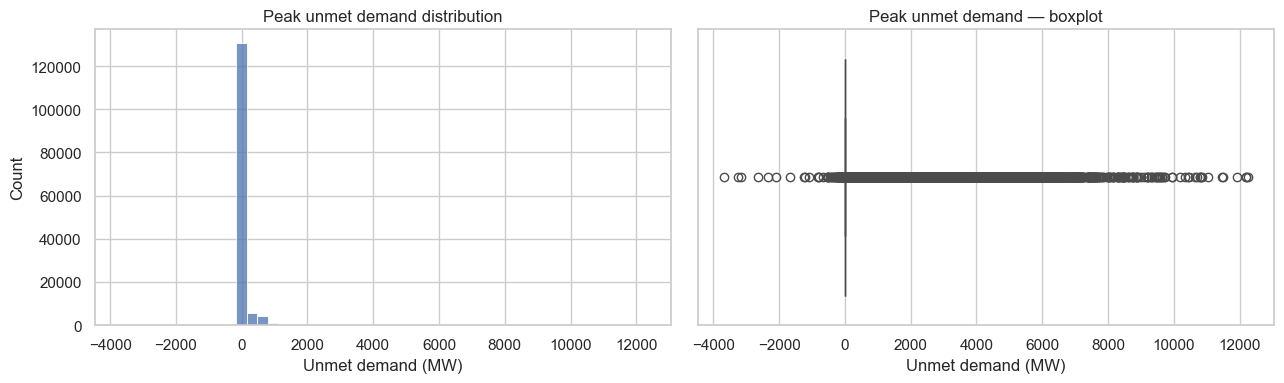

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(values, bins=50, ax=axes[0])
axes[0].set_title("Peak unmet demand distribution")
axes[0].set_xlabel("Unmet demand (MW)")

sns.boxplot(x=values, ax=axes[1])
axes[1].set_title("Peak unmet demand — boxplot")
axes[1].set_xlabel("Unmet demand (MW)")

plt.tight_layout()
plt.show()

## 6. State-wise shortfall analysis

In [71]:
unmet = peak_unmet.melt(
    id_vars="Date",
    var_name="State",
    value_name="Unmet_MW"
).dropna(subset=["Date", "Unmet_MW"])

state_summary = unmet.groupby("State")["Unmet_MW"].agg(
    Mean_MW="mean",
    Median_MW="median",
    Maximum_MW="max",
    Observations="count",
)

positive_frequency = (
    unmet.assign(Positive=unmet["Unmet_MW"].gt(0))
    .groupby("State")["Positive"]
    .mean() * 100
)

state_summary["Positive_frequency_pct"] = positive_frequency

display(state_summary.sort_values("Mean_MW", ascending=False))

,Mean_MW,Median_MW,Maximum_MW,Observations,Positive_frequency_pct
State,,,,,
Total,1977.353075,838.0,12251.0,3951,96.254113
Uttar Pradesh,720.628066,0.0,6120.0,3955,49.380531
Jammu and Kashmir,313.791150,374.0,1219.0,3955,80.859671
Karnataka,161.200152,0.0,2000.0,3952,29.023279
Tamil Nadu,155.148026,0.0,2910.0,3952,17.586032
Andhra Pradesh,106.484312,0.0,3800.0,3952,11.740891
Bihar,75.189128,0.0,1738.0,3955,29.582807
Maharashtra,70.194690,0.0,2986.0,3955,30.063211
Assam,69.456131,39.0,473.0,3955,73.097345


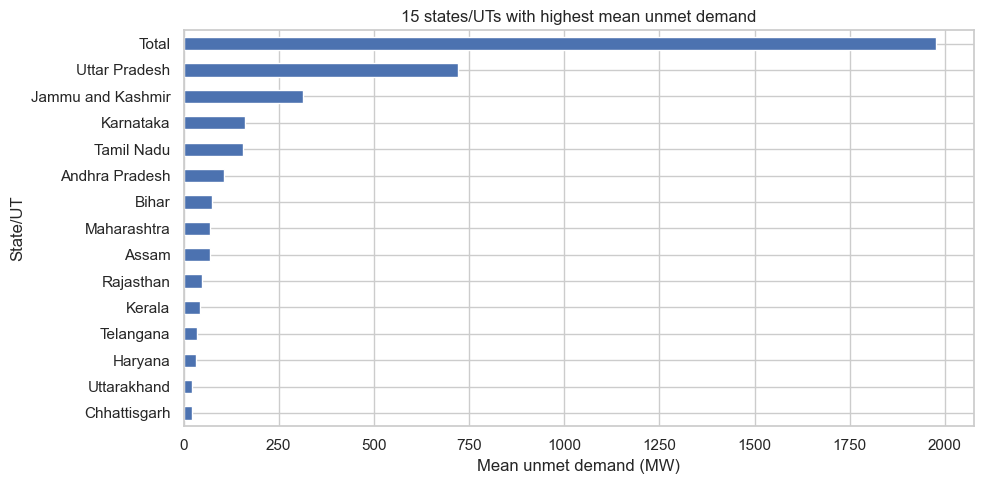

In [72]:
state_summary["Mean_MW"].nlargest(15).sort_values().plot(kind="barh")
plt.title("15 states/UTs with highest mean unmet demand")
plt.xlabel("Mean unmet demand (MW)")
plt.ylabel("State/UT")
plt.tight_layout()
plt.show()

## 7. Shortfall patterns over time

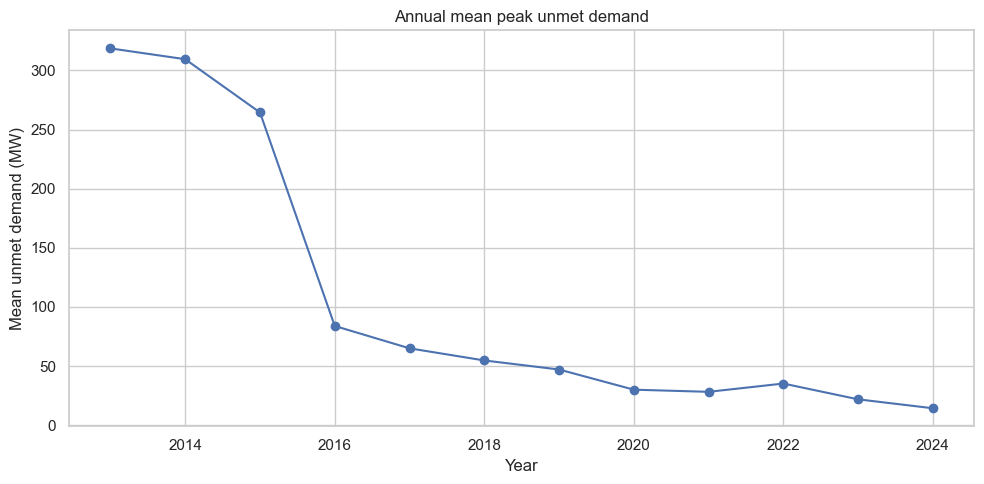

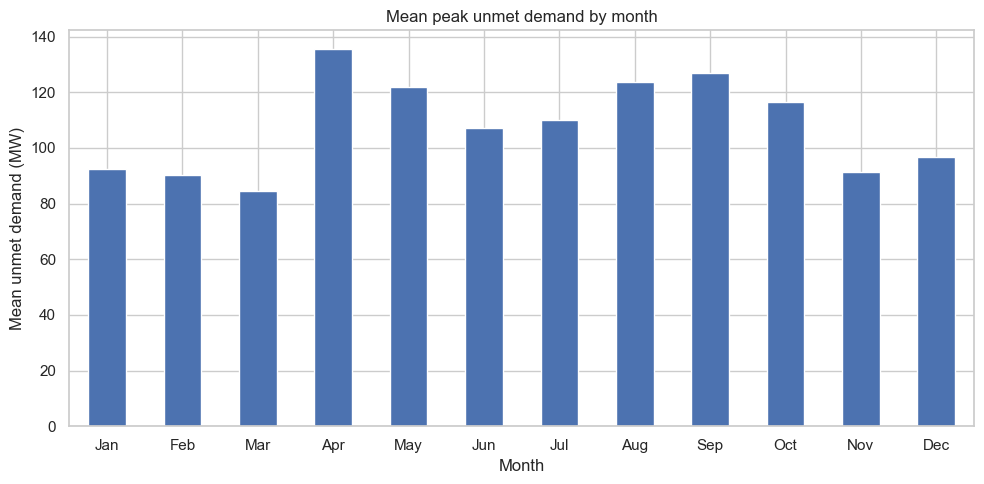

In [73]:
unmet["Year"] = unmet["Date"].dt.year
unmet["Month"] = unmet["Date"].dt.month

annual = unmet.groupby("Year")["Unmet_MW"].mean()
monthly = unmet.groupby("Month")["Unmet_MW"].mean().reindex(range(1, 13))

annual.plot(marker="o")
plt.title("Annual mean peak unmet demand")
plt.xlabel("Year")
plt.ylabel("Mean unmet demand (MW)")
plt.tight_layout()
plt.show()

monthly.plot(kind="bar")
plt.title("Mean peak unmet demand by month")
plt.xlabel("Month")
plt.ylabel("Mean unmet demand (MW)")
plt.xticks(
    range(12),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    rotation=0,
)
plt.tight_layout()
plt.show()

## 8. Compare corrected and original datasets

This comparison checks matched date/state values and reports how often the corrected dataset differs. The files contain repeated dates, so this cell matches rows using the date plus their occurrence order. It does not delete repeated rows; review the reported duplicate counts and unmatched keys before interpreting the comparison.

In [74]:
def compare_versions(original, corrected, name):
    original = original.copy()
    corrected = corrected.copy()

    states = [col for col in original.columns
              if col != "Date" and col in corrected.columns]

    if not states:
        raise ValueError(f"{name}: no matching state columns found.")

    # Keep valid dates and preserve row order when dates repeat.
    for df in (original, corrected):
        df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
        df.dropna(subset=["Date"], inplace=True)
        df.sort_values("Date", kind="stable", inplace=True)
        df["Occurrence"] = df.groupby("Date").cumcount()

    print(f"\n{name}")
    print("Repeated-date rows in original:", int(original["Date"].duplicated().sum()))
    print("Repeated-date rows in corrected:", int(corrected["Date"].duplicated().sum()))

    # Match by date plus occurrence number, rather than Date alone.
    original = original.set_index(["Date", "Occurrence"])[states].sort_index()
    corrected = corrected.set_index(["Date", "Occurrence"])[states].sort_index()

    print("Unmatched original date-row keys:", len(original.index.difference(corrected.index)))
    print("Unmatched corrected date-row keys:", len(corrected.index.difference(original.index)))

    common_keys = original.index.intersection(corrected.index).sort_values()
    original = original.loc[common_keys]
    corrected = corrected.loc[common_keys]

    valid = original.notna() & corrected.notna()
    difference = corrected - original

    matched_count = int(valid.to_numpy().sum())
    changed_count = int((difference.ne(0) & valid).to_numpy().sum())

    print("Matched date-state values:", matched_count)
    print("Changed matched values:", changed_count)

    absolute_difference = difference.abs().where(valid).to_numpy().ravel()
    absolute_difference = absolute_difference[pd.notna(absolute_difference)]

    if len(absolute_difference):
        print("Maximum absolute change:", absolute_difference.max())
    else:
        print("No matched numeric values found.")

    return difference


peak_met_diff = compare_versions(peak_met, corrected_peak_met, "Peak met (MW)")
energy_diff = compare_versions(daily_energy, corrected_daily_energy, "Daily energy met (MU)")


Peak met (MW)
Repeated-date rows in original: 55
Repeated-date rows in corrected: 55
Unmatched original date-row keys: 0
Unmatched corrected date-row keys: 0
Matched date-state values: 144429
Changed matched values: 206
Maximum absolute change: 99974.33333333333

Daily energy met (MU)
Repeated-date rows in original: 55
Repeated-date rows in corrected: 55
Unmatched original date-row keys: 0
Unmatched corrected date-row keys: 0
Matched date-state values: 144429
Changed matched values: 197
Maximum absolute change: 2054.766666666668


## 9. Daily energy analysis

count    144429.000000
mean        189.579184
std         569.071234
min          -0.300000
25%           7.000000
50%          58.200000
75%         167.000000
max        5224.300000
dtype: float64

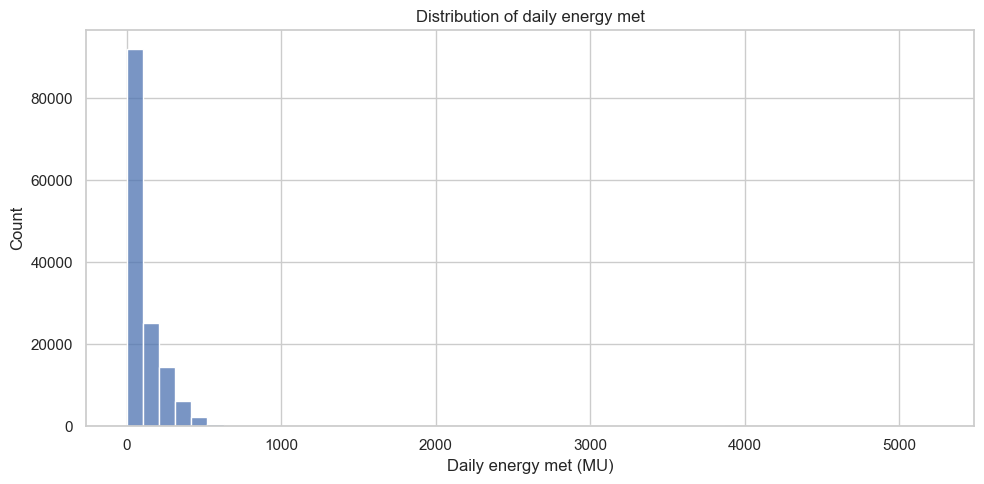

In [75]:
energy_values = corrected_daily_energy.drop(columns="Date").to_numpy().ravel()
energy_values = pd.Series(energy_values).dropna()

display(energy_values.describe())

sns.histplot(energy_values, bins=50)
plt.title("Distribution of daily energy met")
plt.xlabel("Daily energy met (MU)")
plt.tight_layout()
plt.show()

## 10. Audit the state-wise meteorological files

These CSVs contain weather variables. This cell checks file coverage, shapes, column names, missing cells, and duplicate rows without combining the files.

In [76]:
state_files = sorted(STATE.glob("*.csv"))
print("State/UT CSV files:", len(state_files))

state_audit_rows = []

for file in state_files:
    df = pd.read_csv(file)
    date_columns = [col for col in df.columns if col.strip().lower() == "date"]

    state_audit_rows.append({
        "State/UT": file.stem,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing cells": int(df.isna().sum().sum()),
        "Duplicate rows": int(df.duplicated().sum()),
        "Date column": date_columns[0] if date_columns else None,
        "Column names": list(df.columns),
    })

state_audit = pd.DataFrame(state_audit_rows)
display(state_audit)

print("Distinct schemas:", state_audit["Column names"].apply(tuple).nunique())

State/UT CSV files: 36


,State/UT,Rows,Columns,Missing cells,Duplicate rows,Date column,Column names
0,Andaman_and_Nicobar,16554,22,291,0,date,"[date, 10m_u_component_of_wind_min, 10m_u_comp..."
1,Andhra_Pradesh,16554,22,291,0,date,"[date, 10m_u_component_of_wind_min, 10m_u_comp..."
2,Arunachal_Pradesh,16554,22,291,0,date,"[date, 10m_u_component_of_wind_min, 10m_u_comp..."
3,Assam,16554,22,291,0,date,"[date, 10m_u_component_of_wind_min, 10m_u_comp..."
4,Bihar,16554,22,291,0,date,"[date, 10m_u_component_of_wind_min, 10m_u_comp..."
5,Chandigarh,16554,22,291,0,date,"[date, 10m_u_component_of_wind_min, 10m_u_comp..."
6,Chhattisgarh,16554,22,291,0,date,"[date, 10m_u_component_of_wind_min, 10m_u_comp..."
7,Dadra_and_Nagar_Haveli,16554,22,291,0,date,"[date, 10m_u_component_of_wind_min, 10m_u_comp..."
8,Daman_and_Diu,16554,22,291,0,date,"[date, 10m_u_component_of_wind_min, 10m_u_comp..."
9,Goa,16554,22,291,0,date,"[date, 10m_u_component_of_wind_min, 10m_u_comp..."


Distinct schemas: 1


## 11. Inspect the UTCI dataset

In [77]:
utci = pd.read_csv(DERIVED / "weighted_daily_mean_utci_india.csv")

print("Shape:", utci.shape)
print("Columns:", utci.columns.tolist())
print("Missing cells:", int(utci.isna().sum().sum()))

display(utci.head())
display(utci.describe(include="all").T)

Shape: (15341, 2)
Columns: ['date', 'utci']
Missing cells: 0


,date,utci
0,1979-01-01,289.552548
1,1979-01-02,290.018459
2,1979-01-03,290.186134
3,1979-01-04,289.628056
4,1979-01-05,289.347465


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,15341,15341,1979-01-01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
utci,15341.0,NaN,NaN,NaN,298.450506,5.357342,285.138599,293.518717,300.43068,302.67944,307.76862


## 12. Candidate shortfall thresholds

These percentiles are preliminary descriptions of positive observations, not validated operational severity levels. State-level values must later be scaled to the total load of each synthetic grid.

In [78]:
positive_unmet = unmet.loc[unmet["Unmet_MW"] > 0, "Unmet_MW"]
display(positive_unmet.quantile([0.50, 0.75, 0.90, 0.95, 0.99]))

0.50      46.0
0.75     338.0
0.90     810.0
0.95    1860.0
0.99    5650.5
Name: Unmet_MW, dtype: float64

## 13. Save EDA outputs

In [79]:
quality_report.to_csv(OUTPUT / "electricity_quality_report.csv", index=False)
state_summary.to_csv(OUTPUT / "state_unmet_summary.csv")
annual.rename("Mean_unmet_MW").to_csv(OUTPUT / "annual_unmet_summary.csv")
state_audit.to_csv(OUTPUT / "state_data_audit.csv", index=False)
peak_met_diff.to_csv(OUTPUT / "peak_met_correction_differences.csv")
energy_diff.to_csv(OUTPUT / "energy_correction_differences.csv")

print("Saved EDA outputs to:", OUTPUT)

Saved EDA outputs to: C:\Users\Admin\Projects\Urja_Niyam\data\processed\eda


## Initial interpretation checklist

After running the notebook, record the answers to these questions in your project notes:

1. What are the actual date ranges and missing-data levels of the electricity datasets?
2. How common are positive unmet-demand observations, and what does their distribution look like?
3. Which states/UTs show the highest mean shortfall and highest shortfall frequency?
4. How much do the corrected peak-met and daily-energy datasets differ from their original versions?
5. Do all state-wise meteorological files share a consistent schema?

**Scope reminder:** these data are daily and state-level; they do not directly provide feeder-level 15-minute shortfall profiles. Those profiles need a suitable higher-resolution source or documented synthetic assumptions.